In [1]:
# Importing Necessary Libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import geopandas as gpd

warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
# Data from Google Cloud Storage
bucket = 'mlprojectbucket1kjor'
ais_train_path = f'gs://{bucket}/ais_train.csv'

In [3]:
# Load the AIS Data (initial load from CSV)
ais_data = pd.read_csv(ais_train_path, delimiter='|')

# Convert the AIS dataset to Parquet format for efficient processing
parquet_path = 'data/ais_train.parquet'
ais_data.to_parquet(parquet_path, index=False, compression='gzip')

# Load the AIS Data from Parquet for further use
ais_data = pd.read_parquet(parquet_path)

# Create 'moored' feature
# A vessel is considered moored if it has no significant change in position for a series of timestamps
ais_data['moored'] = (ais_data['sog'] < 0.5)  # Assuming a vessel is moored if Speed Over Ground is less than 0.5 knots

# Handle Missing Values for portId
ais_data['portId'].fillna(method='ffill', inplace=True)

# Overview of the Dataset
print("Dataset Shape:", ais_data.shape)
print("\nFirst 5 Rows:")
print(ais_data.head())
print("\nColumn Information:")
ais_data.info()

# Descriptive Statistics
print("\nDescriptive Statistics for Numeric Columns:")
print(ais_data.describe())

# Handling Missing Data
print("\nMissing Values in Each Column:")
print(ais_data.isna().sum())

Dataset Shape: (1522065, 12)

First 5 Rows:
                  time    cog   sog  rot  heading  navstat       etaRaw  \
0  2024-01-01 00:00:25  284.0   0.7    0       88        0  01-09 23:00   
1  2024-01-01 00:00:36  109.6   0.0   -6      347        1  12-29 20:00   
2  2024-01-01 00:01:45  111.0  11.0    0      112        0  01-02 09:00   
3  2024-01-01 00:03:11   96.4   0.0    0      142        1  12-31 20:00   
4  2024-01-01 00:03:51  214.0  19.7    0      215        0  01-25 12:00   

   latitude  longitude                  vesselId                    portId  \
0 -34.74370  -57.85130  61e9f3a8b937134a3c4bfdf7  61d371c43aeaecc07011a37f   
1   8.89440  -79.47939  61e9f3d4b937134a3c4bff1f  634c4de270937fc01c3a7689   
2  39.19065  -76.47567  61e9f436b937134a3c4c0131  61d3847bb7b7526e1adf3d19   
3 -34.41189  151.02067  61e9f3b4b937134a3c4bfe77  61d36f770a1807568ff9a126   
4  35.88379   -5.91636  61e9f41bb937134a3c4c0087  634c4de270937fc01c3a74f3   

   moored  
0   False  
1    True  


# Exploratory Data Analysis (EDA)

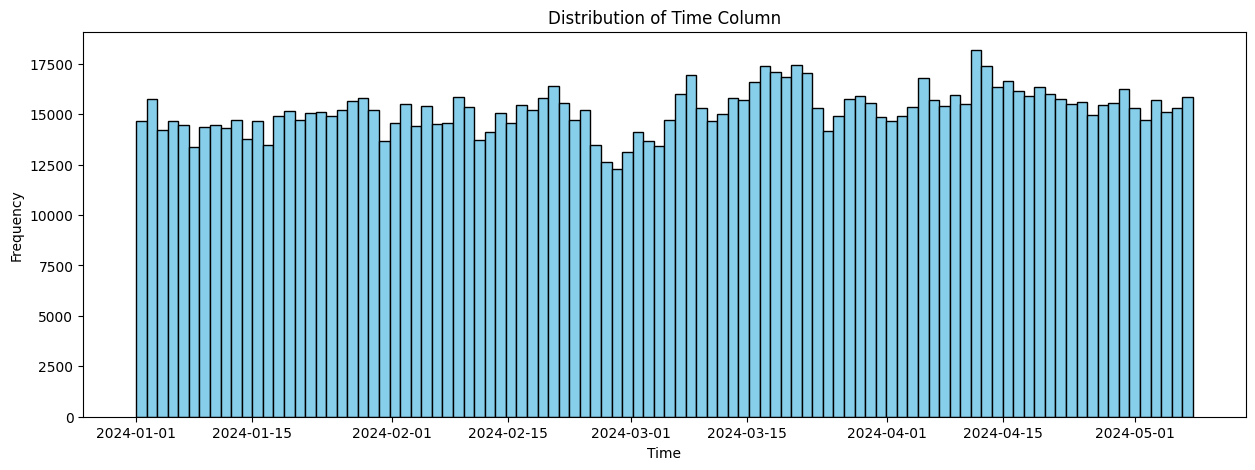

In [4]:
## 2. Visualize Timestamps Distribution
# Converting TIME to datetime type
ais_data['time'] = pd.to_datetime(ais_data['time'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
plt.figure(figsize=(15, 5))
plt.title("Distribution of Time Column")
plt.hist(ais_data['time'], bins=100, color='skyblue', edgecolor='black')
plt.xlabel('Time')
plt.ylabel('Frequency')
plt.show()

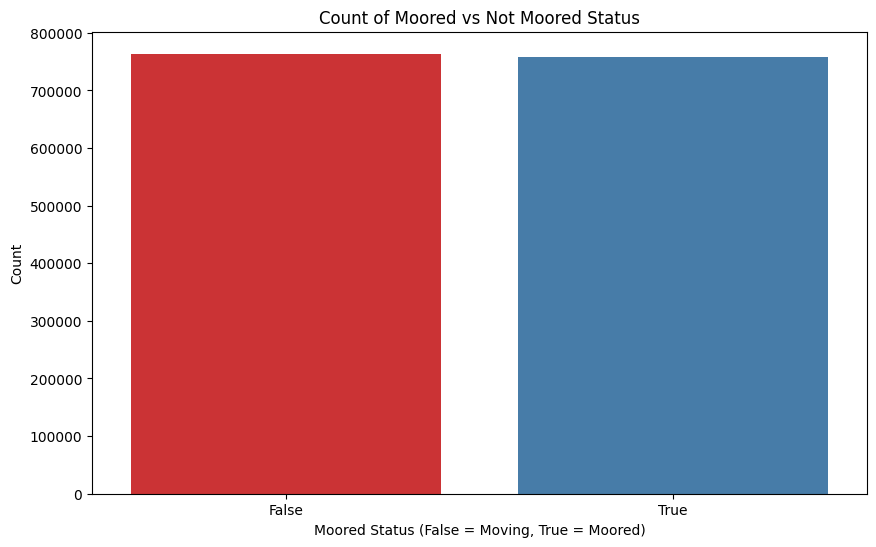

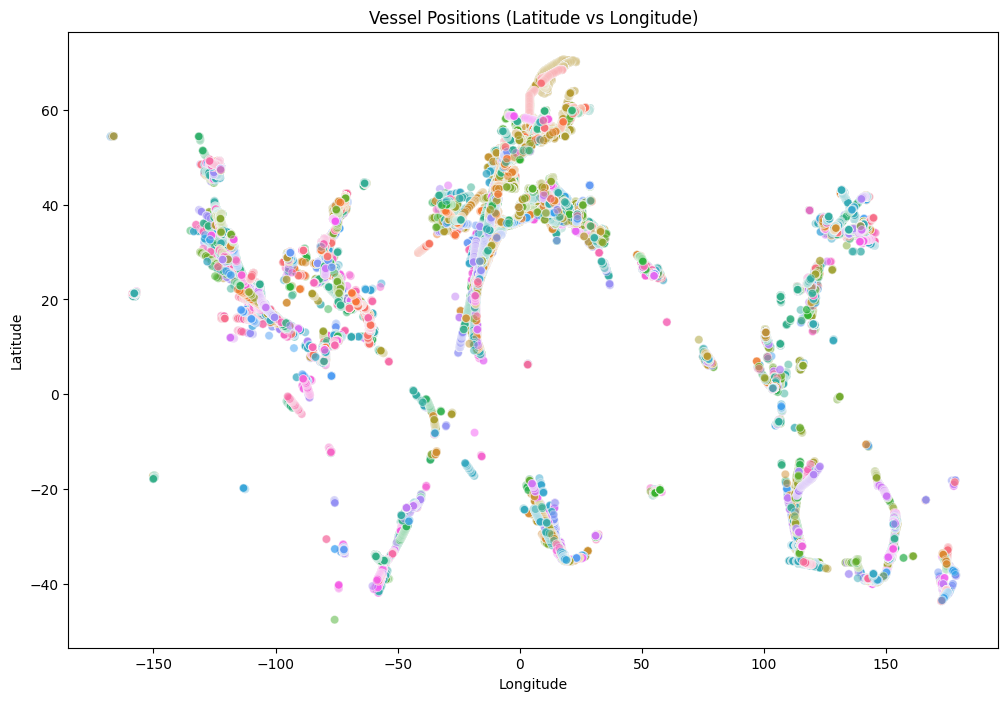

In [5]:
## 3. Analyzing Vessel Movements
### Moored Status Analysis
# Analyzing how often vessels are moored
plt.figure(figsize=(10, 6))
sns.countplot(x='moored', data=ais_data, palette='Set1')
plt.title('Count of Moored vs Not Moored Status')
plt.xlabel('Moored Status (False = Moving, True = Moored)')
plt.ylabel('Count')
plt.show()


### Latitude and Longitude Distribution
plt.figure(figsize=(12, 8))
sns.scatterplot(data=ais_data, x='longitude', y='latitude', hue='vesselId', alpha=0.5, legend=False)
plt.title('Vessel Positions (Latitude vs Longitude)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

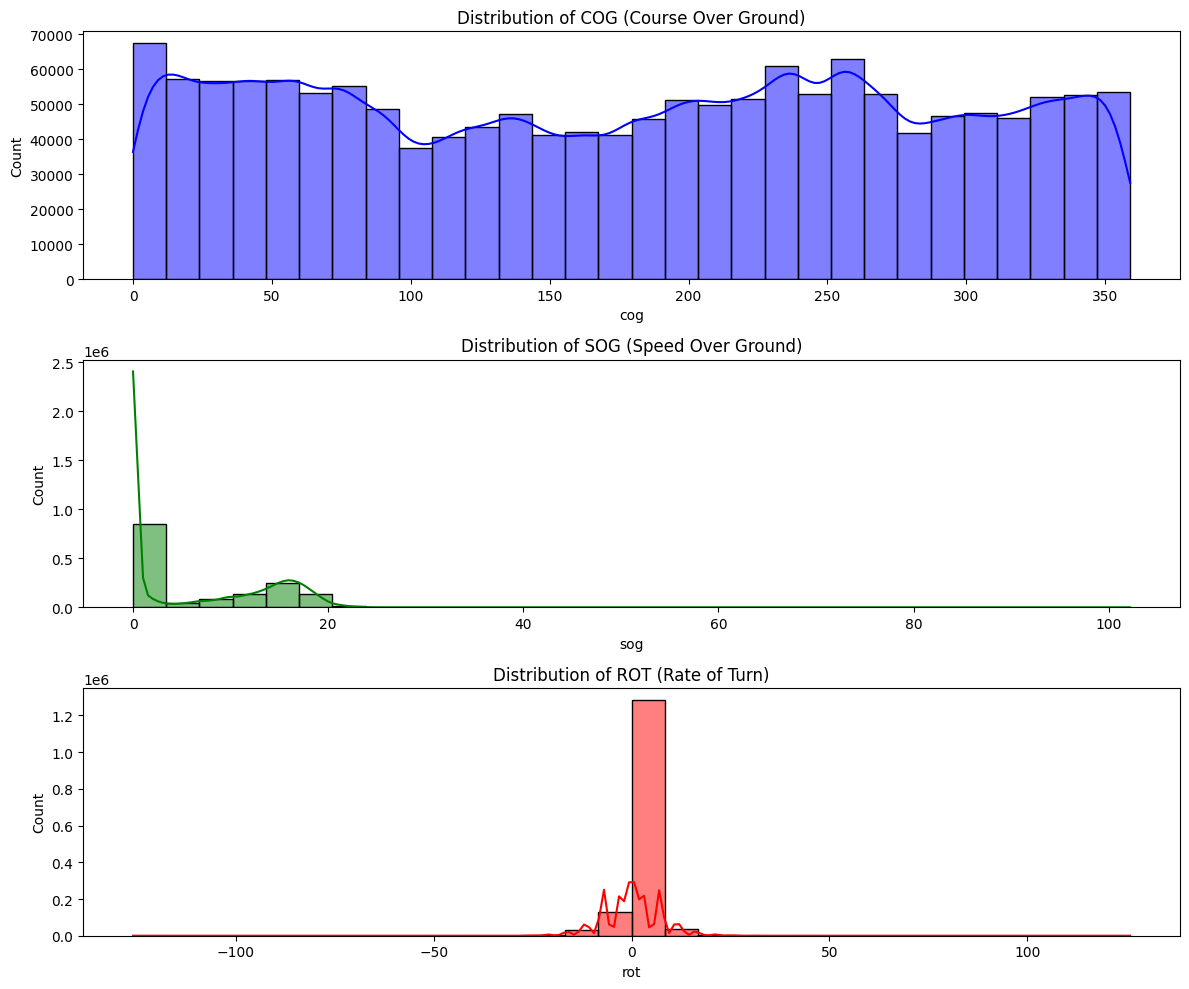

In [6]:
## 4. COG, SOG, and ROT Analysis
plt.figure(figsize=(12, 10))
plt.subplot(3, 1, 1)
plt.title('Distribution of COG (Course Over Ground)')
sns.histplot(ais_data[ais_data['cog'] <= 359]['cog'], kde=True, color='blue', bins=30)

plt.subplot(3, 1, 2)
plt.title('Distribution of SOG (Speed Over Ground)')
sns.histplot(ais_data[ais_data['sog'] <= 102.2]['sog'], kde=True, color='green', bins=30)

plt.subplot(3, 1, 3)
plt.title('Distribution of ROT (Rate of Turn)')
sns.histplot(ais_data[(ais_data['rot'] != -128) & (ais_data['rot'].between(-126, 126))]['rot'], kde=True, color='red', bins=30)

plt.tight_layout()
plt.show()

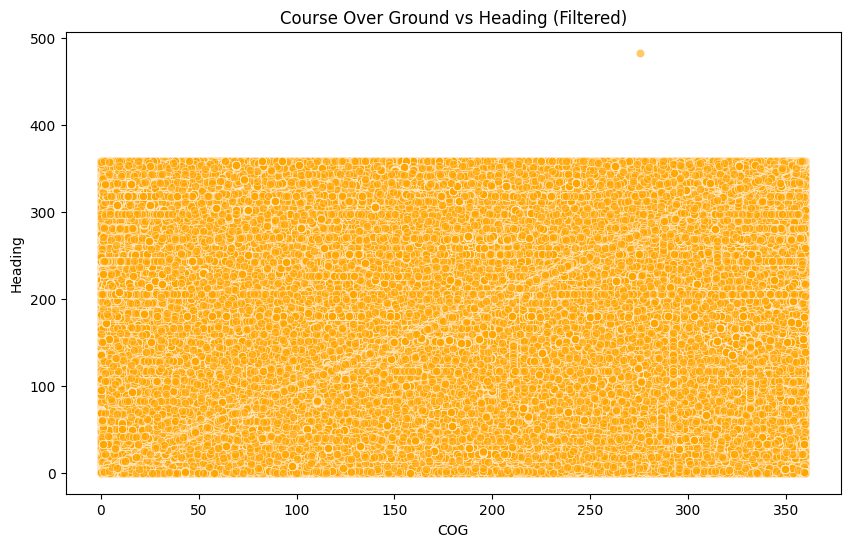

In [7]:
## 5. Heading vs Course Analysis (Filtered)
filtered_data = ais_data[ais_data['heading'] != 511]
plt.figure(figsize=(10, 6))
sns.scatterplot(data=filtered_data, x='cog', y='heading', alpha=0.6, color='orange', legend=False)
plt.title('Course Over Ground vs Heading (Filtered)')
plt.xlabel('COG')
plt.ylabel('Heading')
plt.show()

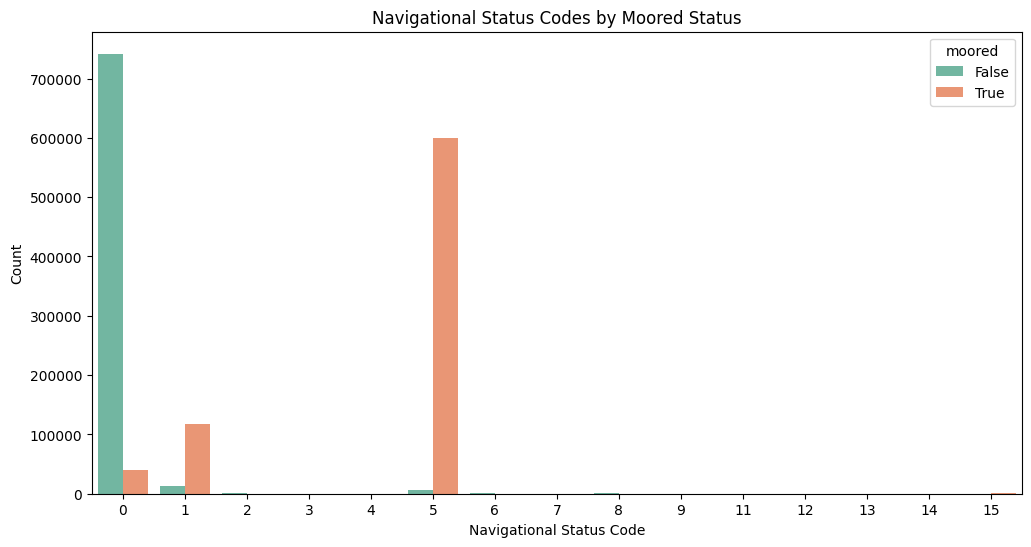

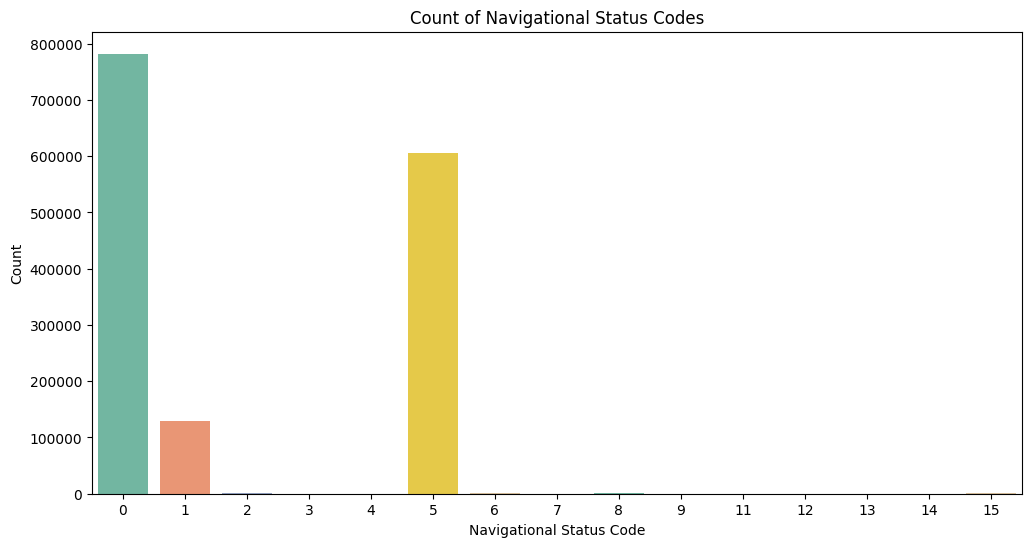

In [8]:
## 6. Navigational Status Analysis
# Analyze moored feature correlation with navigational status
plt.figure(figsize=(12, 6))
sns.countplot(x='navstat', hue='moored', data=ais_data, palette='Set2')
plt.title('Navigational Status Codes by Moored Status')
plt.xlabel('Navigational Status Code')
plt.ylabel('Count')
plt.show()

plt.figure(figsize=(12, 6))
sns.countplot(x='navstat', data=ais_data, palette='Set2')
plt.title('Count of Navigational Status Codes')
plt.xlabel('Navigational Status Code')
plt.ylabel('Count')
plt.show()

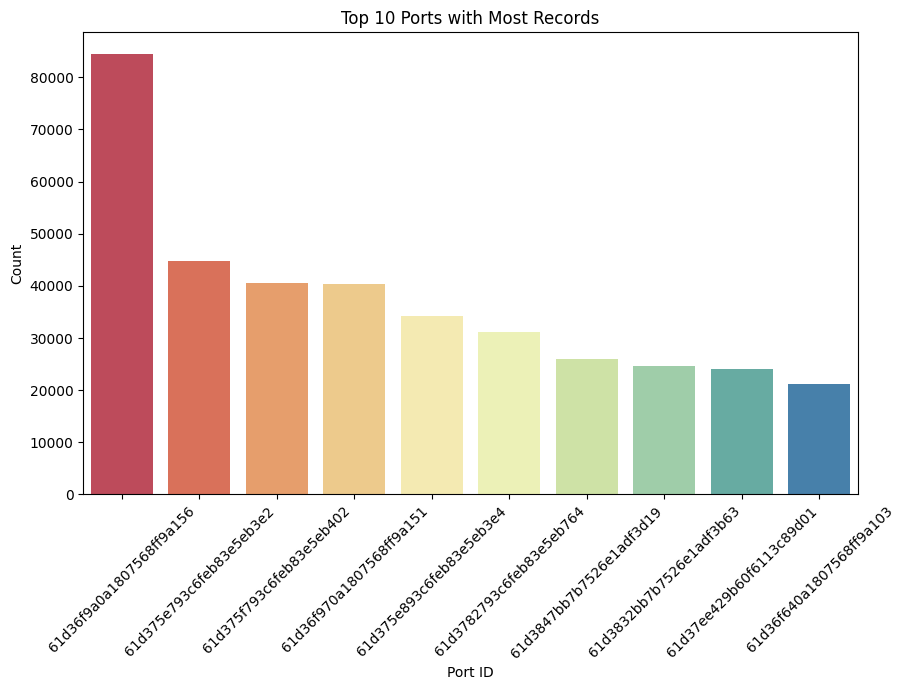

In [9]:
## 7. Analyzing Vessel Ports
plt.figure(figsize=(10, 6))
sns.countplot(x='portId', data=ais_data, order=ais_data['portId'].value_counts().iloc[:10].index, palette='Spectral')
plt.title('Top 10 Ports with Most Records')
plt.xlabel('Port ID')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

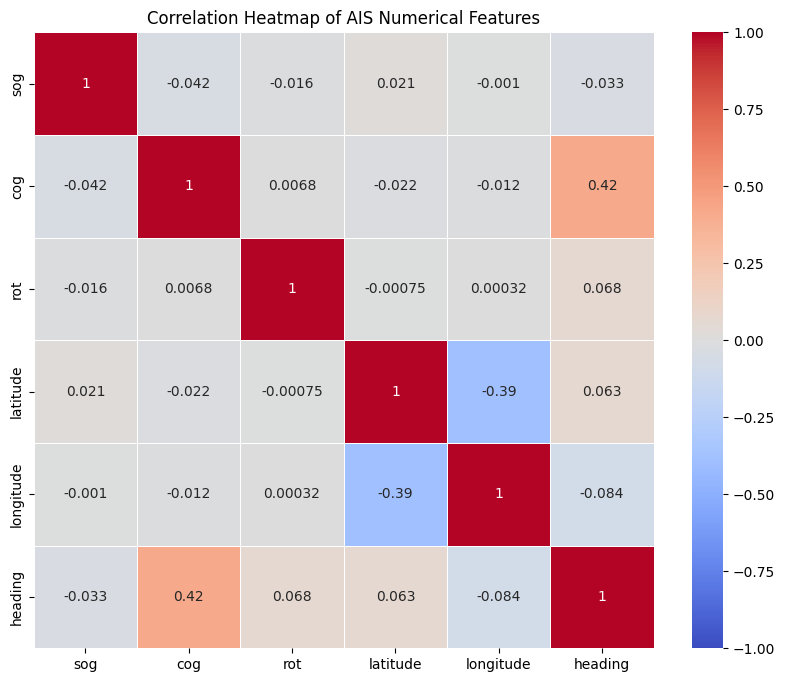

In [7]:
#7 Correlation analysis
#Handling Missing Values
# Forward fill for SOG, COG, ROT to smooth vessel movement
ais_data[['sog', 'cog', 'rot']] = ais_data[['sog', 'cog', 'rot']].fillna(method='ffill')

# Correlation Analysis
# Selecting relevant numerical columns for correlation analysis
numerical_columns = ['sog', 'cog', 'rot', 'latitude', 'longitude', 'heading']
correlation_matrix = ais_data[numerical_columns].corr()

# Plotting the Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of AIS Numerical Features')
plt.show()